# Plate Reader Data Analysis: Synthesis Rate

1) CD1 - Conrad's first run of the experimental protocol (2025-05-13)
2) CD2 - Conrad's second run of the experimental protocol (2025-05-28)
3) AL1 - my first run of the experimental protocol (2025-10-21)


## Setup


In [1]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (AUTOFLUORESCENCE_ORDER, BARS_PNG_YMIN, CIRCUIT_WELLS,
                               FIGURE_DPI, PDF_DPI, PL2_FIT_CUTOFF, PNG_DPI, REPLICATES,
                               REPLICATE_MARKERS, SAMPLING_METHOD, TAGS, WELLS,
                               biomass_and_floor, blank_series,
                               dg_dt, load_plate_series, replicate_mean, rpu_bands,
                               set_rpu_scale, smooth)


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bioutils import transform


## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI
plt.rcParams["savefig.dpi"] = FIGURE_DPI

# Opacity of the exponential-growth window shading
EXP_WINDOW_ALPHA = 0.05


## OUTPUT ##

# growth-rate summary in, synthesis rates and the two PDFs out
OUT_DIR = Path("out")
OUT_DIR.mkdir(exist_ok=True)

# Panels ~10 min over 276 pages, bars ~1 min over 16
GENERATE_PLOTS_PDF = True
GENERATE_BARS_PDF = True
GENERATE_BARS_PNG = True



## CIRCUITS ##

# Circuit shown in the inline figures
CIRCUIT = 72

# Group the inline figures follow; the PDFs sweep every group
SAMPLE_GROUP = f"Circuit {CIRCUIT}"

# Growth-rate methods carried to the CSV, SG first
GROWTH_RATE_METHODS = ("sg", "polyfit", "window")
assert SAMPLING_METHOD in GROWTH_RATE_METHODS


## DETECTION FLOOR ##


# Corrected groups; pL2 defines the calibration
ALL_GROUPS = {
    **{f"Circuit {circuit}": (CIRCUIT_WELLS[circuit], "black") for circuit in range(1, 93)},
    "pRPU": (WELLS["pRPU"], "purple"),
    # WT: plasmid-free, an out-of-sample zero
    "WT": (WELLS["wt"], "navy"),
}

# pL2: corrected against its own curve, a self-consistency check
CALIBRANT_GROUPS = {"pL2": (WELLS["pL2"], "orange")}
PHI_GROUPS = {**ALL_GROUPS, **CALIBRANT_GROUPS}

# Subset drawn inline
GROUPS = {name: PHI_GROUPS[name] for name in (SAMPLE_GROUP, "pRPU")}


In [2]:
# Load data
od_raw, fl_raw, t_minutes = load_plate_series()

for tag in TAGS:
    print(f"{tag}: plate shape={od_raw[tag].shape}, runtime={t_minutes[tag][-1]:.0f} min")


Rep1: plate shape=(16, 24, 41), runtime=480 min
Rep2: plate shape=(16, 24, 41), runtime=480 min
Rep3: plate shape=(16, 24, 41), runtime=480 min


In [3]:
# Pooled blank and detection threshold per plate
POOLED_BLANK, DETECTION_THRESHOLD, POOLED_BLANK_FL = blank_series(od_raw, fl_raw)


# Subtract the plate's pooled blank, for OD and F.

biomass, fl_no_bg, above_floor = {}, {}, {}

for name, (wells, colour) in PHI_GROUPS.items():
    biomass[name], fl_no_bg[name], above_floor[name] = {}, {}, {}
    for rep in REPLICATES:
        tag = rep["tag"]
        rows, cols = zip(*wells)

        # smoothed, pooled-blank-corrected, and the floor tested on that same series
        biomass[name][tag], above_floor[name][tag] = biomass_and_floor(
            od_raw[tag][list(rows), list(cols), :], POOLED_BLANK[tag],
            DETECTION_THRESHOLD[tag])
        # F smoothed before the blank comes off, as OD is
        fl_no_bg[name][tag] = (smooth(fl_raw[tag][list(rows), list(cols), :])
                               - POOLED_BLANK_FL[tag])


In [4]:
# One pL2 autofluorescence cubic per (replicate, condition), as in analyse_pr_autof_pL2.ipynb

autofl_coeffs = {}
autofl_od_range = {}

for rep in REPLICATES:
    tag = rep["tag"]
    autofl_coeffs[tag], autofl_od_range[tag] = {}, {}
    for well in range(4):
        condition = rep["cond_labels"][well]
        # PL2_FIT_CUTOFF drops stationary phase
        cutoff = PL2_FIT_CUTOFF[rep["label"]][condition]
        od_well = biomass["pL2"][tag][well][:cutoff]
        fl_well = fl_no_bg["pL2"][tag][well][:cutoff]
        autofl_coeffs[tag][well], autofl_od_range[tag][well], keep = (
            transform.fit_autofluorescence(od_well, fl_well, above_floor["pL2"][tag][well][:cutoff],
                                           order=AUTOFLUORESCENCE_ORDER))

        low, high = autofl_od_range[tag][well]
        residual = fl_well[keep] - transform.autofluorescence_at(
            autofl_coeffs[tag][well], od_well[keep])
        print(f"{tag} ({rep['label']}) {condition:>4}: {int(keep.sum()):3d} points over "
              f"{low:.4f}-{high:.4f}, RMSE {np.sqrt((residual ** 2).mean()):5.2f}")


def predict_autofluorescence(tag, well, od):
    """pL2 autofluorescence at a given OD, from that condition's own cubic."""
    return transform.autofluorescence_at(autofl_coeffs[tag][well], od)


Rep1 (CD1) None:  22 points over 0.0151-0.3257, RMSE  2.15
Rep1 (CD1)  aTc:  22 points over 0.0185-0.3124, RMSE  2.32
Rep1 (CD1) IPTG:  16 points over 0.0228-0.2793, RMSE  2.36
Rep1 (CD1) Both:  22 points over 0.0182-0.3073, RMSE  0.89
Rep2 (CD2) None:  19 points over 0.0151-0.3258, RMSE  1.53
Rep2 (CD2)  aTc:  18 points over 0.0207-0.3117, RMSE  2.42
Rep2 (CD2) IPTG:  22 points over 0.0295-0.3337, RMSE  1.46
Rep2 (CD2) Both:  19 points over 0.0161-0.2953, RMSE  1.43
Rep3 (AL1) None:  17 points over 0.0277-0.3342, RMSE  0.96
Rep3 (AL1)  aTc:  18 points over 0.0297-0.3600, RMSE  1.87
Rep3 (AL1) IPTG:  22 points over 0.0246-0.3605, RMSE  1.26
Rep3 (AL1) Both:  19 points over 0.0280-0.3647, RMSE  1.37


In [5]:
# G = F - autofluorescence, its Savitzky-Golay derivative, and phi = dG/dt / OD
# G is kept signed; clip only when reporting a level

G, dG_dt, phi, computable = {}, {}, {}, {}

for name in PHI_GROUPS:
    G[name], dG_dt[name], phi[name], computable[name] = {}, {}, {}, {}
    for rep in REPLICATES:
        tag = rep["tag"]
        od_well = biomass[name][tag]

        # Computable above the floor; the fitted OD range does not gate G
        inside = above_floor[name][tag].copy()
        corrected = fl_no_bg[name][tag] - np.stack(
            [predict_autofluorescence(tag, well, od_well[well]) for well in range(4)])
        corrected = np.where(inside, corrected, np.nan)
        G[name][tag] = corrected
        computable[name][tag] = np.isfinite(corrected)

        # Savitzky-Golay on the real time grid
        derivative = dg_dt(corrected, t_minutes[tag])
        dG_dt[name][tag] = derivative
        with np.errstate(invalid="ignore", divide="ignore"):
            phi[name][tag] = derivative / np.where(od_well > 0, od_well, np.nan)

# what the calibration range and the G > 0 rule cost us
records = []
for rep in REPLICATES:
    tag = rep["tag"]
    for name in PHI_GROUPS:
        for well in range(4):
            usable = computable[name][tag][well]
            index = np.flatnonzero(usable)
            od_well = biomass[name][tag][well]
            records.append({
                "Rep": rep["label"],
                "Group": name,
                "Condition": rep["cond_labels"][well],
                "n usable": int(usable.sum()),
                "first": None if not len(index) else round(float(t_minutes[tag][index[0]])),
                "last": None if not len(index) else round(float(t_minutes[tag][index[-1]])),
                "gaps": 0 if not len(index) else int(np.sum(np.diff(index) > 1)),
                "n negative G": int(np.sum(usable & (G[name][tag][well] < 0))),
                "n derivative": int(np.isfinite(dG_dt[name][tag][well]).sum()),
            })

computable_window = pd.DataFrame(records)
print(f"{len(computable_window)} wells: median {computable_window['n usable'].median():.0f} "
      f"usable timepoints, {int((computable_window['gaps'] > 0).sum())} with gaps, "
      f"{int((computable_window['n usable'] == 0).sum())} with none")

# WARNING: negative G is kept, so say where it happens
negative = computable_window[computable_window["n negative G"] > 0]
if len(negative):
    print(f"WARNING: {len(negative)} of {len(computable_window)} wells carry negative G at "
          f"{int(negative['n negative G'].sum())} of "
          f"{int(computable_window['n usable'].sum())} computable timepoints "
          f"(worst well: {int(negative['n negative G'].max())}). The autofluorescence curve "
          f"over-predicts there. Kept signed, not clipped or dropped -- see the note above.")
computable_window.head()


1140 wells: median 41 usable timepoints, 20 with gaps, 1 with none


,Rep,Group,Condition,n usable,first,last,gaps,n negative G,n derivative
0,CD1,Circuit 1,None,41,0.0,480.0,0,0,35
1,CD1,Circuit 1,aTc,41,0.0,480.0,0,0,35
2,CD1,Circuit 1,IPTG,41,0.0,480.0,0,0,35
3,CD1,Circuit 1,Both,41,0.0,480.0,0,0,35
4,CD1,Circuit 2,None,41,0.0,480.0,0,0,35


In [6]:
# Sampled timepoint, from analyse_pr_biomass.ipynb

growth_summary = pd.read_csv(OUT_DIR / "analyse_pr_biomass.csv",
                             keep_default_na=False, na_values=[""])


def read_timepoints(column):
    """Per-group, per-replicate times from one biomass column, and their nearest grid indices."""
    times, indices = {}, {}
    for name in PHI_GROUPS:
        times[name], indices[name] = {}, {}
        for rep in REPLICATES:
            tag = rep["tag"]
            match = growth_summary[(growth_summary["Group"] == name)
                                   & (growth_summary["Rep"] == rep["label"])]
            times[name][tag] = [
                float(match[match["Condition"] == rep["cond_labels"][well]][column].iloc[0])
                for well in range(4)]
            # Nearest grid point: the CSV rounds to 0.1 min
            indices[name][tag] = [
                int(np.argmin(np.abs(t_minutes[tag] - value))) for value in times[name][tag]]
    return times, indices


# every method's sampled point, not only the pipeline's
t_sampled, t_sampled_index = {}, {}
for method in GROWTH_RATE_METHODS:
    t_sampled[method], t_sampled_index[method] = read_timepoints(f"t_sampled_{method}")

# The 95% growth window, for the panel shading
t_window_first, _ = read_timepoints(f"t_window_first_{SAMPLING_METHOD}")
t_window_last, _ = read_timepoints(f"t_window_last_{SAMPLING_METHOD}")


## Corrected Fluorescence Over Time


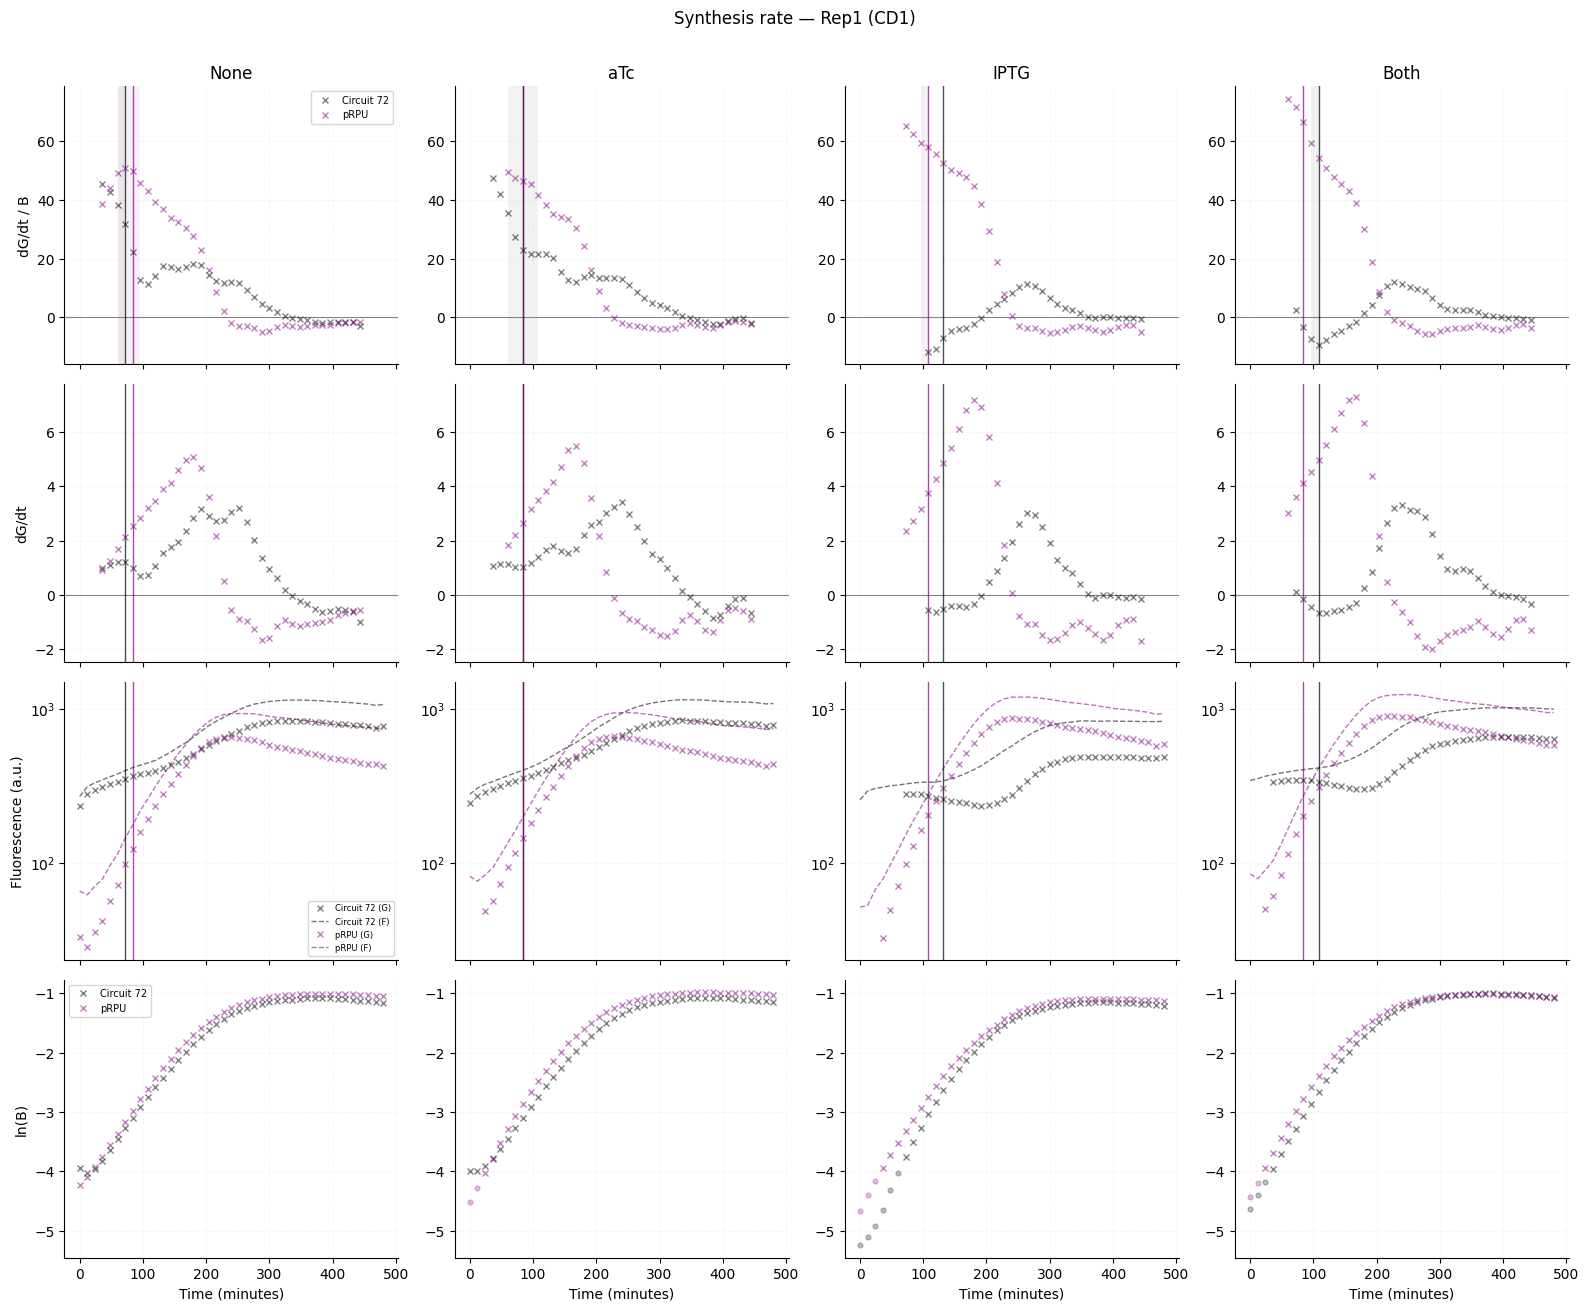

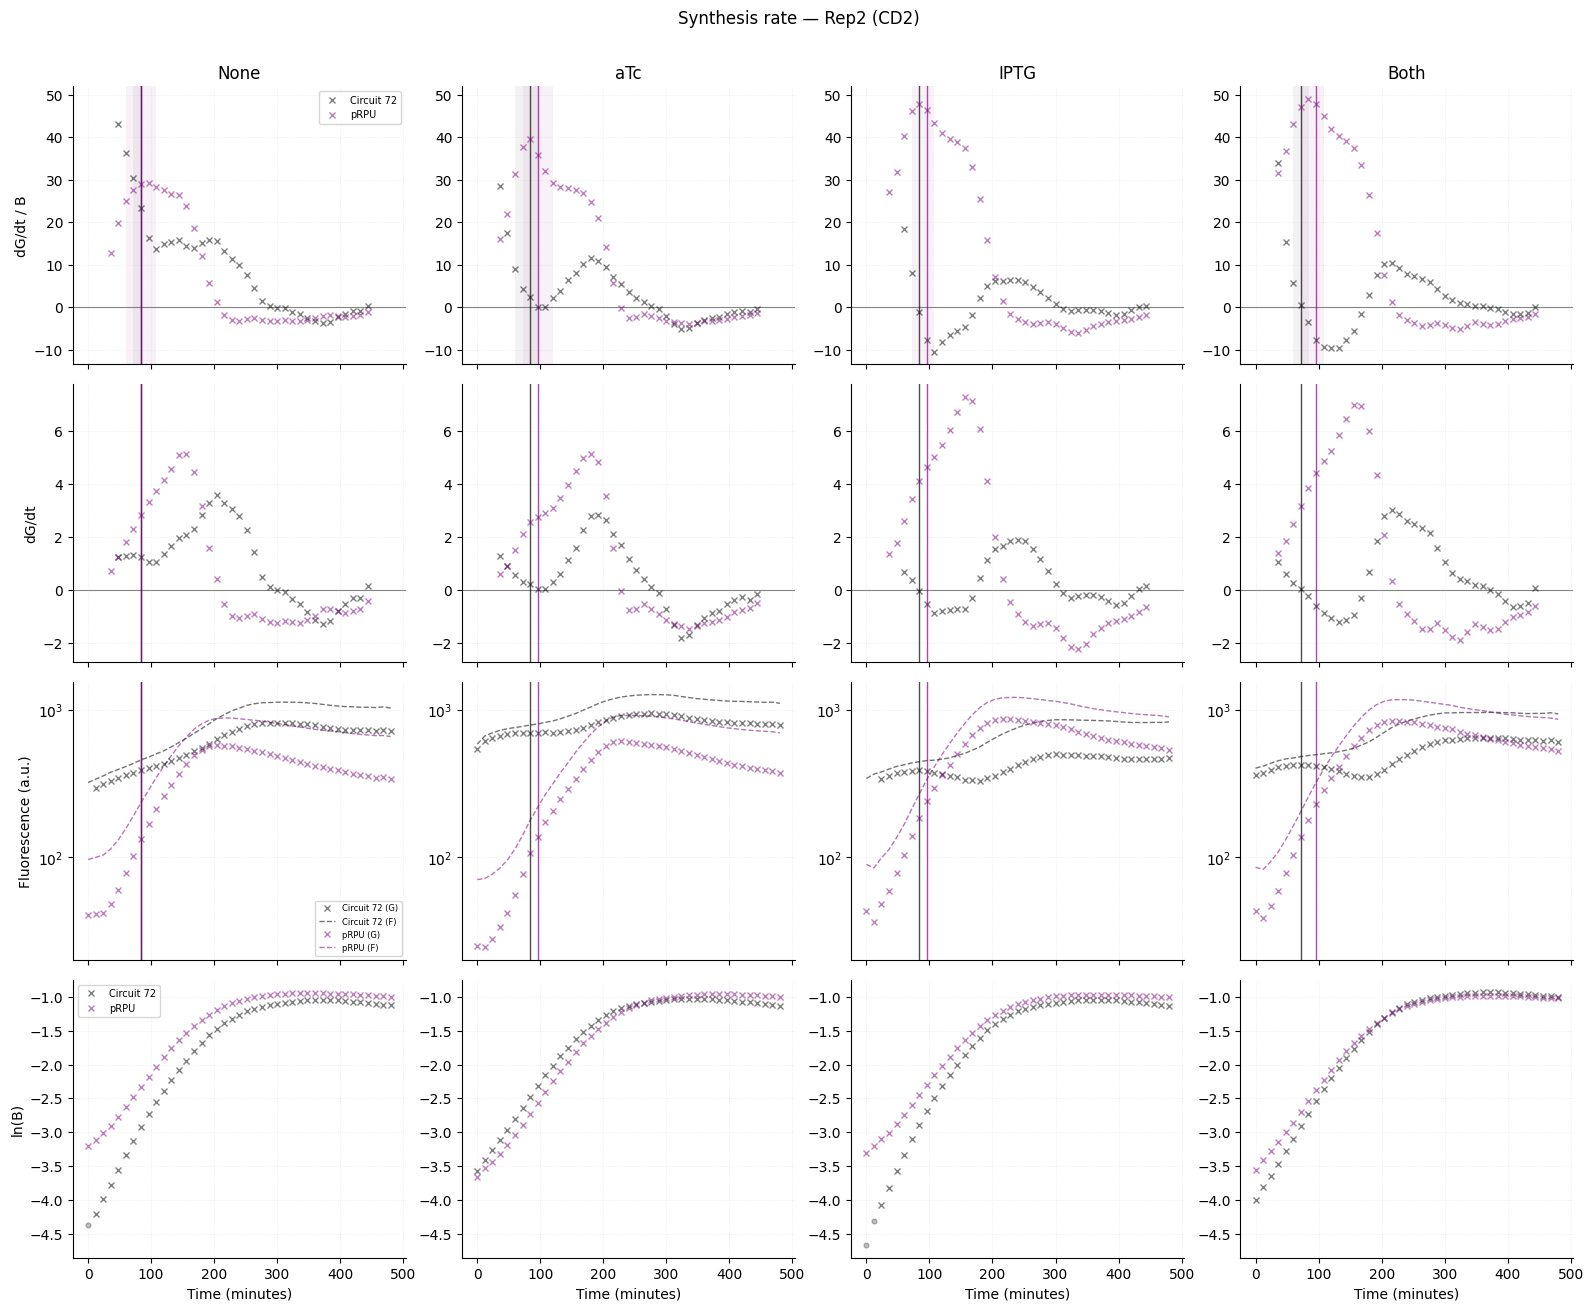

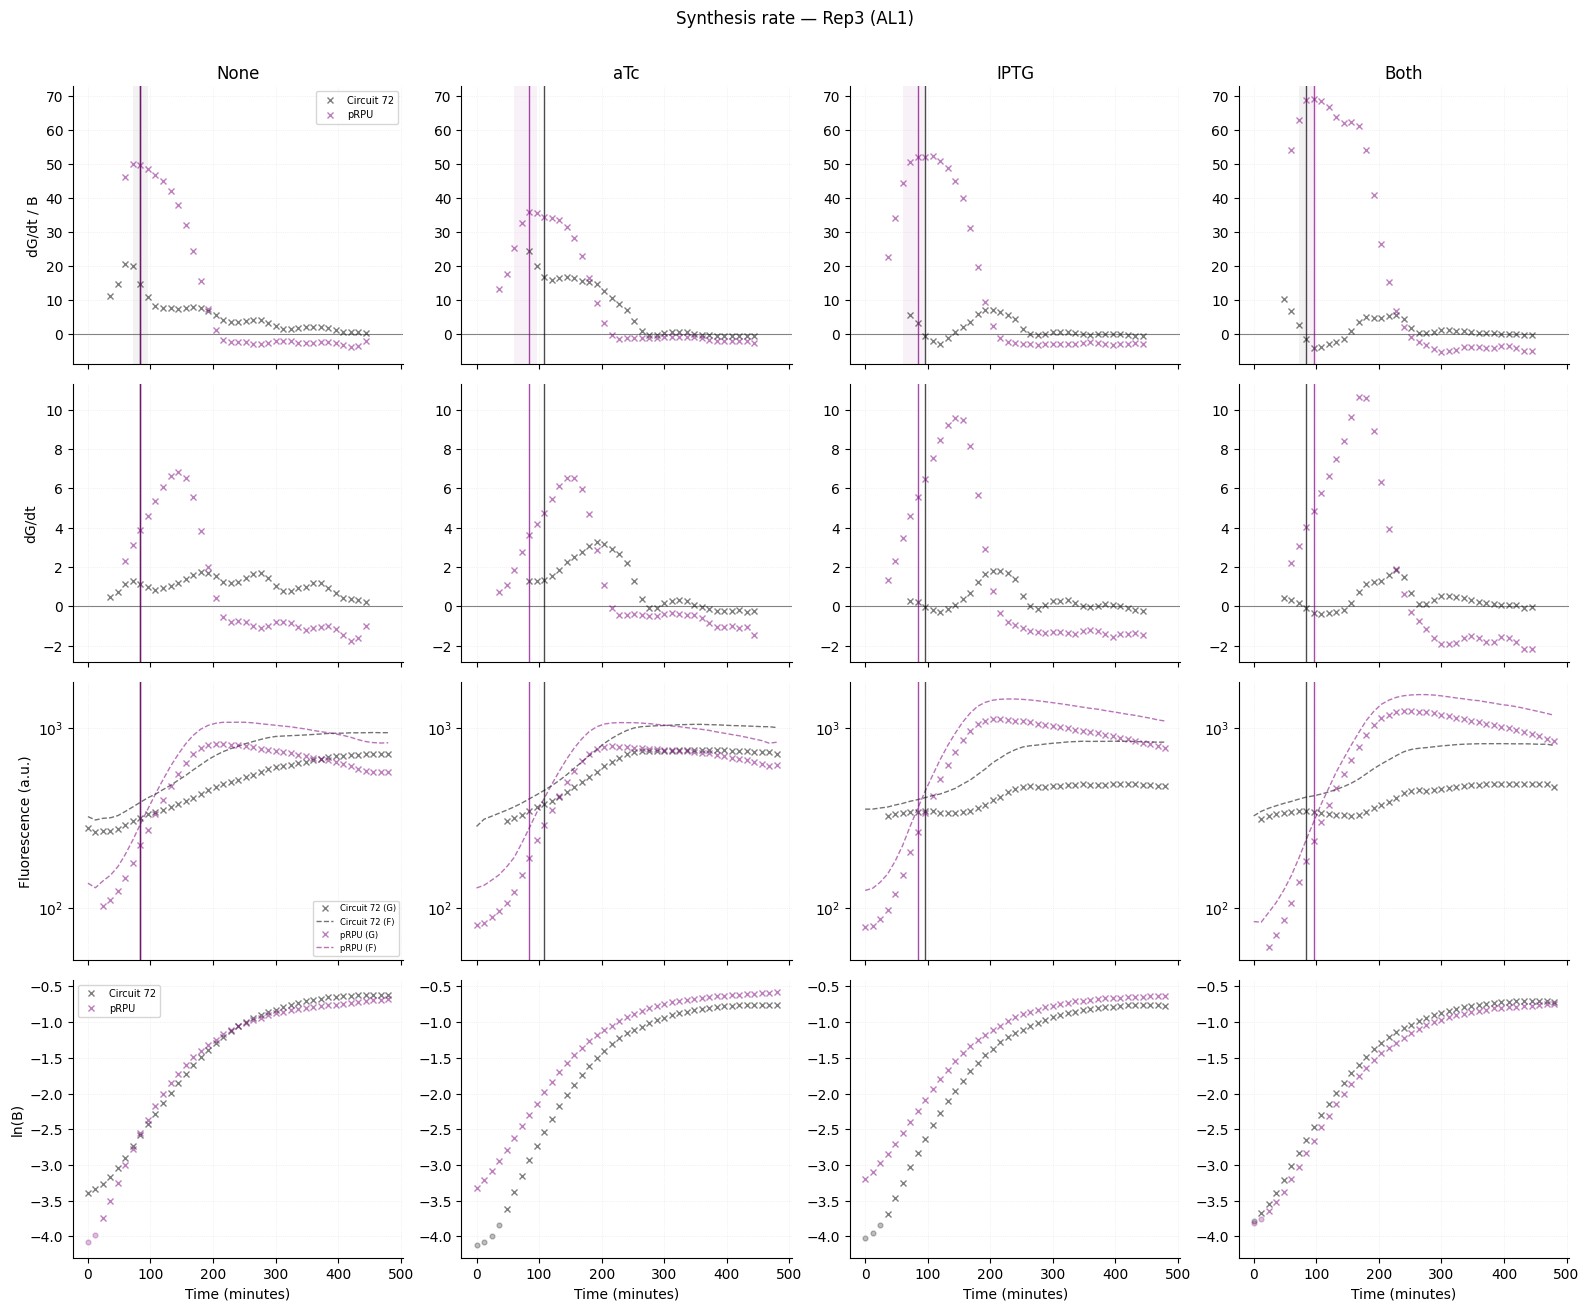

In [7]:
# Per-replicate 4x4 grid: phi, dG/dt, fluorescence and ln(B) down, conditions across

for rep in REPLICATES:
    tag = rep["tag"]
    fig, axes = plt.subplots(4, 4, figsize=(16, 13), sharex=True)
    for row in range(4):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])

    for well in range(4):
        ax_phi, ax_deriv, ax_g, ax_od = axes[:, well]

        for name, (wells, colour) in GROUPS.items():
            usable = computable[name][tag][well]
            # Exponential-growth window, synthesis-rate row only
            window = (t_window_first[name][tag][well], t_window_last[name][tag][well])
            if np.isfinite(window).all():
                ax_phi.axvspan(*window, color=colour, alpha=EXP_WINDOW_ALPHA, zorder=0,
                               linewidth=0)
            for ax, values, series in ((ax_phi, phi[name][tag][well], name),
                                       (ax_deriv, dG_dt[name][tag][well], name),
                                       (ax_g, G[name][tag][well], f"{name} (G)")):
                ax.plot(t_minutes[tag][usable], values[usable], "x",
                        color=colour, ms=4, alpha=0.5, zorder=2, label=series)
                ax.plot(t_minutes[tag][~usable], values[~usable], "o",
                        color=colour, ms=3.5, alpha=0.25, zorder=1)
                ax.axvline(t_sampled[SAMPLING_METHOD][name][tag][well],
                           color=colour, lw=1, alpha=0.7)

            # Blank-corrected F on the G row too
            ax_g.plot(t_minutes[tag], fl_no_bg[name][tag][well],
                      color=colour, ls="--", lw=1.0, alpha=0.55, zorder=1,
                      label=f"{name} (F)")

        for name, (wells, colour) in GROUPS.items():
            above = above_floor[name][tag][well]
            with np.errstate(invalid="ignore", divide="ignore"):
                ln_od = np.log(biomass[name][tag][well])
            ax_od.plot(t_minutes[tag][above], ln_od[above], "x",
                       color=colour, ms=4, alpha=0.5, zorder=2, label=name)
            ax_od.plot(t_minutes[tag][~above], ln_od[~above], "o",
                       color=colour, ms=3.5, alpha=0.25, zorder=1)

        ax_phi.axhline(0, color="gray", lw=0.8, zorder=0)
        ax_deriv.axhline(0, color="gray", lw=0.8, zorder=0)
        # Symlog keeps negative G visible
        ax_g.set_yscale("symlog", linthresh=0.1)
        ax_phi.set_title(rep["cond_labels"][well])
        ax_od.set_xlabel("Time (minutes)")
        for ax in (ax_phi, ax_deriv, ax_g, ax_od):
            ax.grid(True, alpha=0.3, linewidth=0.5, ls=":")
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
        if well == 0:
            ax_phi.set_ylabel("dG/dt / B")
            ax_deriv.set_ylabel("dG/dt")
            # G and blank-corrected F share an axis
            ax_g.set_ylabel("Fluorescence (a.u.)")
            ax_g.legend(fontsize=6)
            ax_od.set_ylabel("ln(B)")
            ax_phi.legend(fontsize=7)
            ax_od.legend(fontsize=7)

    fig.suptitle(f"Synthesis rate — {tag} ({rep['label']})", y=1.005)
    plt.tight_layout()
    plt.show()


## RPU at Peak Growth


In [8]:
# RPU: each group's phi at its own sampled timepoint, over pRPU's
# Negative synthesis rates are kept

# One row per (group, replicate, condition), carrying every method
records = []
for rep in REPLICATES:
    tag = rep["tag"]
    for well in range(4):
        for name in PHI_GROUPS:
            # Distance from the sampled point to the nearer edge of phi's window
            usable = np.flatnonzero(np.isfinite(phi[name][tag][well]))
            record = {
                "Group": name,
                "Rep": rep["label"],
                "Condition": rep["cond_labels"][well],
                "n_usable": int(len(usable)),
            }
            for method in GROWTH_RATE_METHODS:
                index = t_sampled_index[method][name][tag][well]
                # pRPU's sampled point moves with the method
                phi_pRPU = phi["pRPU"][tag][well][
                    t_sampled_index[method]["pRPU"][tag][well]]
                record.update({
                    f"t_sampled_{method}": t_sampled[method][name][tag][well],
                    f"biomass_at_sampled_{method}":
                        round(float(biomass[name][tag][well][index]), 5),
                    f"G_at_sampled_{method}": round(float(G[name][tag][well][index]), 3),
                    f"dG_dt_at_sampled_{method}":
                        round(float(dG_dt[name][tag][well][index]), 5),
                    f"synthesis_rate_{method}": round(float(phi[name][tag][well][index]), 4),
                    f"RPU_{method}": round(float(phi[name][tag][well][index] / phi_pRPU), 5),
                    f"margin_{method}": None if not len(usable) else int(
                        min(index - usable[0], usable[-1] - index)),
                })
            records.append(record)

synthesis_rates = pd.DataFrame(records)

# what the pipeline reads out of the three methods the CSV now carries
RPU_COLUMN = f"RPU_{SAMPLING_METHOD}"
SYNTHESIS_RATE_COLUMN = f"synthesis_rate_{SAMPLING_METHOD}"

# Control bands and axis range; read first, the flag needs the WT band
WT_BAND, PL2_BAND, RPU_BAND, RPU_LIMITS = rpu_bands(synthesis_rates, RPU_COLUMN)

# Replicates below the WT band floor are flagged; replicate_mean leaves them out
synthesis_rates["invalid_below_wt"] = synthesis_rates[RPU_COLUMN] < WT_BAND[0]

# Read back with keep_default_na=False, na_values=[""]
synthesis_rates.to_csv(OUT_DIR / "analyse_pr_synthrate.csv", index=False)

_circuits = synthesis_rates[synthesis_rates["Group"].str.startswith("Circuit")]
_inside = (_circuits[RPU_COLUMN] >= WT_BAND[0]) & (_circuits[RPU_COLUMN] <= WT_BAND[1])
print(f"pL2 band {PL2_BAND[0]:.4f} to {PL2_BAND[1]:.4f} RPU (the calibration residual)")
print(f"WT band {WT_BAND[0]:.4f} to {WT_BAND[1]:.4f} RPU; "
      f"{int(_inside.sum())} of {int(_circuits[RPU_COLUMN].notna().sum())} circuit "
      f"wells inside it")
print(f"{int(synthesis_rates['invalid_below_wt'].sum())} wells below that floor, "
      f"marked invalid_below_wt")

finite = synthesis_rates[SYNTHESIS_RATE_COLUMN].notna()
print(f"{len(synthesis_rates)} rows: {int((~finite).sum())} without a computable synthesis rate, "
      f"{int((synthesis_rates[SYNTHESIS_RATE_COLUMN] < 0).sum())} negative, "
      f"{int((synthesis_rates[f'margin_{SAMPLING_METHOD}'] == 0).sum())} sampled on the "
      f"window edge")
synthesis_rates.head()


pL2 band -0.0572 to 0.0947 RPU (the calibration residual)
WT band -0.2088 to 0.0000 RPU; 22 of 1103 circuit wells inside it
5 wells below that floor, marked invalid_below_wt
1140 rows: 1 without a computable synthesis rate, 46 negative, 0 sampled on the window edge


,Group,Rep,Condition,n_usable,t_sampled_sg,biomass_at_sampled_sg,G_at_sampled_sg,dG_dt_at_sampled_sg,synthesis_rate_sg,RPU_sg,...,RPU_polyfit,margin_polyfit,t_sampled_window,biomass_at_sampled_window,G_at_sampled_window,dG_dt_at_sampled_window,synthesis_rate_window,RPU_window,margin_window,invalid_below_wt
0,Circuit 1,CD1,None,35,108.0,0.12283,7764.946,98.00220,797.8470,15.98627,...,14.35655,7.0,120.0,0.13720,8955.872,100.66556,733.7140,14.35655,7.0,False
1,Circuit 2,CD1,None,35,108.0,0.13933,6895.026,68.45799,491.3253,9.84457,...,9.61374,6.0,108.0,0.13933,6895.026,68.45799,491.3253,9.61374,6.0,False
2,Circuit 3,CD1,None,35,108.0,0.11253,461.927,4.35781,38.7246,0.77592,...,0.69901,7.0,120.0,0.12730,515.522,4.54769,35.7242,0.69901,7.0,False
3,Circuit 4,CD1,None,35,108.0,0.10923,996.053,8.23887,75.4245,1.51126,...,1.47583,6.0,120.0,0.12400,1096.129,8.98291,72.4428,1.41749,7.0,False
4,Circuit 5,CD1,None,35,120.0,0.13750,15979.233,170.33206,1238.7786,24.82112,...,22.26736,8.0,120.0,0.13750,15979.233,170.33206,1238.7786,24.23913,7.0,False


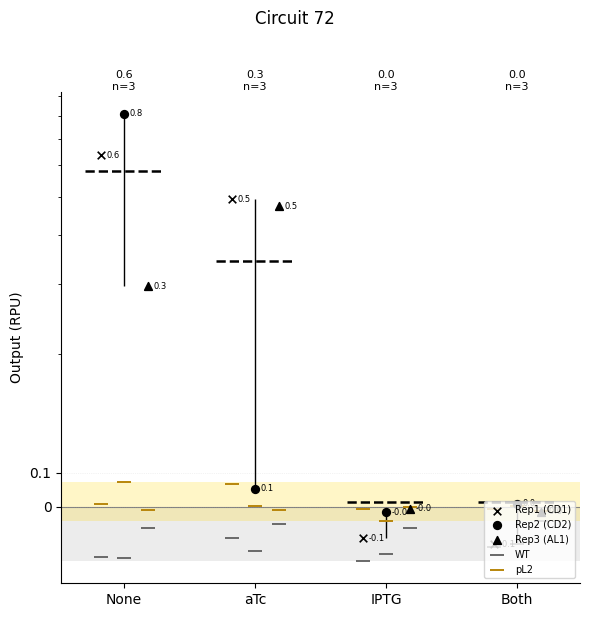

In [9]:
# RPU per inducer condition: dashed tick is the centre, line spans min-max
# (Weissgerber et al. 2015, doi:10.1371/journal.pbio.1002128)

selected = synthesis_rates[synthesis_rates["Group"] == SAMPLE_GROUP]
rpu_matrix = np.array([
    selected[selected["Rep"] == rep["label"]][RPU_COLUMN].to_numpy() for rep in REPLICATES])
rpu_centre, _imputed, _raw = replicate_mean(rpu_matrix, WT_BAND[0], PL2_BAND)
n_per_condition = np.sum(rpu_matrix >= WT_BAND[0], axis=0)
x_centers = np.arange(len(REPLICATES[0]["cond_labels"]))

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xticks(x_centers)
ax.set_xticklabels(REPLICATES[0]["cond_labels"])

# below this width a value cannot be told from zero
ax.axhspan(*WT_BAND, color="gray", alpha=0.15, zorder=0, linewidth=0)
# drawn second so the narrower band stays visible where the two overlap
ax.axhspan(*PL2_BAND, color="gold", alpha=0.22, zorder=0, linewidth=0)
ax.axhline(0, color="gray", lw=0.8, zorder=1)

ax.vlines(x_centers, np.nanmin(rpu_matrix, axis=0), np.nanmax(rpu_matrix, axis=0),
          color="black", lw=1.0, zorder=2)
ax.hlines(rpu_centre, x_centers - 0.3, x_centers + 0.3, color="black", lw=1.8,
          ls="--", zorder=2)

replicate_markers = REPLICATE_MARKERS
replicate_offsets = [-0.18, 0.0, 0.18]
for rep, marker, offset in zip(REPLICATES, replicate_markers, replicate_offsets):
    values = selected[selected["Rep"] == rep["label"]][RPU_COLUMN].to_numpy()
    ax.scatter(x_centers + offset, values, marker=marker, color="black", s=30, linewidths=1.2,
               zorder=3, label=f"{rep['tag']} ({rep['label']})")
    for x, value in zip(x_centers + offset, values):
        if np.isnan(value):
            continue
        ax.annotate(f"{value:.1f}", xy=(x, value), xytext=(4, 0),
                    textcoords="offset points", color="black", ha="left", va="center",
                    fontsize=6, zorder=4)

# Both control bands, each in its own colour
for control, control_colour in (("WT", "dimgray"), ("pL2", "darkgoldenrod")):
    control_selected = synthesis_rates[synthesis_rates["Group"] == control]
    for rep, offset in zip(REPLICATES, replicate_offsets):
        ax.scatter(x_centers + offset,
                   control_selected[control_selected["Rep"] == rep["label"]][RPU_COLUMN],
                   marker="_", color=control_colour, s=90, linewidths=1.4, zorder=2,
                   label=control if rep is REPLICATES[0] else None)

# Linear across the bands, log outside
set_rpu_scale(ax, RPU_BAND, RPU_LIMITS)
ax.set_ylabel("Output (RPU)")
ax.legend(fontsize=7, loc="lower right")
ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for x, value, n in zip(x_centers, rpu_centre, n_per_condition):
    ax.text(x, ax.get_ylim()[1], f"{value:.1f}\nn={n}",
            ha="center", va="bottom", fontsize=8)

fig.suptitle(SAMPLE_GROUP, y=1.02)
plt.tight_layout()
plt.show()


## All Circuits


In [10]:
import time
from matplotlib.backends.backend_pdf import PdfPages


def plot_synthrate_page(group, rep):
    """One page: phi, dG/dt, fluorescence and ln(B) for one group on one replicate."""
    tag = rep["tag"]
    # PHI_GROUPS includes pL2
    page_groups = {name: PHI_GROUPS[name] for name in (group, "pRPU")}
    figure, axes = plt.subplots(4, 4, figsize=(16, 13), sharex=True)
    for row in range(4):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])

    for well in range(4):
        ax_phi, ax_deriv, ax_g, ax_od = axes[:, well]

        for name, (wells, colour) in page_groups.items():
            usable = computable[name][tag][well]
            # Exponential-growth window, synthesis-rate row only
            window = (t_window_first[name][tag][well], t_window_last[name][tag][well])
            if np.isfinite(window).all():
                ax_phi.axvspan(*window, color=colour, alpha=EXP_WINDOW_ALPHA, zorder=0,
                               linewidth=0)
            for ax, values, series in ((ax_phi, phi[name][tag][well], name),
                                       (ax_deriv, dG_dt[name][tag][well], name),
                                       (ax_g, G[name][tag][well], f"{name} (G)")):
                ax.plot(t_minutes[tag][usable], values[usable], "x",
                        color=colour, ms=4, alpha=0.5, zorder=2, label=series)
                ax.plot(t_minutes[tag][~usable], values[~usable], "o",
                        color=colour, ms=3.5, alpha=0.25, zorder=1)
                ax.axvline(t_sampled[SAMPLING_METHOD][name][tag][well],
                           color=colour, lw=1, alpha=0.7)

            # Blank-corrected F on the G row too
            ax_g.plot(t_minutes[tag], fl_no_bg[name][tag][well],
                      color=colour, ls="--", lw=1.0, alpha=0.55, zorder=1,
                      label=f"{name} (F)")

        for name, (wells, colour) in {**page_groups, **CALIBRANT_GROUPS}.items():
            above = above_floor[name][tag][well]
            with np.errstate(invalid="ignore", divide="ignore"):
                ln_od = np.log(biomass[name][tag][well])
            ax_od.plot(t_minutes[tag][above], ln_od[above], "x",
                       color=colour, ms=4, alpha=0.5, zorder=2, label=name)
            ax_od.plot(t_minutes[tag][~above], ln_od[~above], "o",
                       color=colour, ms=3.5, alpha=0.25, zorder=1)

        ax_phi.axhline(0, color="gray", lw=0.8, zorder=0)
        ax_deriv.axhline(0, color="gray", lw=0.8, zorder=0)
        # Symlog keeps negative G visible
        ax_g.set_yscale("symlog", linthresh=0.1)
        ax_phi.set_title(rep["cond_labels"][well])
        ax_od.set_xlabel("Time (minutes)")
        for ax in (ax_phi, ax_deriv, ax_g, ax_od):
            ax.grid(True, alpha=0.3, linewidth=0.5, ls=":")
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
        if well == 0:
            ax_phi.set_ylabel("dG/dt / B")
            ax_deriv.set_ylabel("dG/dt")
            # G and blank-corrected F share an axis
            ax_g.set_ylabel("Fluorescence (a.u.)")
            ax_g.legend(fontsize=6)
            ax_od.set_ylabel("ln(B)")
            ax_phi.legend(fontsize=7)
            ax_od.legend(fontsize=7)

    figure.suptitle(f"{group} — {tag} ({rep['label']})", y=0.995)
    figure.subplots_adjust(left=0.05, right=0.99, top=0.94, bottom=0.05,
                           hspace=0.15, wspace=0.12)
    return figure


if not GENERATE_PLOTS_PDF:
    print("GENERATE_PLOTS_PDF is False: skipping the per-circuit panel PDF")
else:
    path = OUT_DIR / "analyse_pr_synthrate_plots.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        # Pages for pL2 and WT
        groups = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2", "WT"]
        for group in groups:
            for rep in REPLICATES:
                figure = plot_synthrate_page(group, rep)
                pdf.savefig(figure, dpi=PDF_DPI)
                plt.close(figure)
    print(f"{path}: {len(groups) * len(REPLICATES)} pages, "
          f"{time.perf_counter() - started:.0f}s, "
          f"{path.stat().st_size / 1e6:.1f} MB")


out/analyse_pr_synthrate_plots.pdf: 282 pages, 196s, 10.1 MB


In [11]:
# Six circuits per page, sharing one symlog y-range so circuits are comparable across pages.

BARS_PER_PAGE = 6

def draw_rpu(ax, group, ylim=RPU_LIMITS):
    """The inline bar chart for one group, drawn into a supplied axis."""
    selected = synthesis_rates[synthesis_rates["Group"] == group]
    matrix = np.array([selected[selected["Rep"] == rep["label"]][RPU_COLUMN].to_numpy()
                       for rep in REPLICATES])
    # Replicates below the WT band floor: faded, and left out of the range line
    invalid = np.array([selected[selected["Rep"] == rep["label"]]["invalid_below_wt"].to_numpy()
                        for rep in REPLICATES])
    valid = np.where(invalid, np.nan, matrix)
    # the centre the classifier reads, over the same wells drawn solid
    centre, _imputed, _raw = replicate_mean(matrix, WT_BAND[0], PL2_BAND)
    centres = np.arange(4)
    ax.set_xticks(centres)
    ax.set_xticklabels(REPLICATES[0]["cond_labels"])
    ax.axhspan(*WT_BAND, color="gray", alpha=0.15, zorder=0, linewidth=0)
    # drawn second so the narrower band stays visible where the two overlap
    ax.axhspan(*PL2_BAND, color="gold", alpha=0.22, zorder=0, linewidth=0)
    ax.vlines(centres, np.nanmin(valid, axis=0), np.nanmax(valid, axis=0),
              color="black", lw=0.9, zorder=2)
    # Imputed centres drawn like any other
    ax.hlines(centre, centres - 0.3, centres + 0.3, color="black", lw=1.5, ls="--",
              zorder=2)
    for row, (rep, marker, offset) in enumerate(zip(REPLICATES, REPLICATE_MARKERS,
                                                    [-0.18, 0.0, 0.18])):
        ax.scatter(np.arange(4) + offset, valid[row], marker=marker, color="black", s=22,
                   linewidths=1.0, zorder=3, label=f"{rep['tag']} ({rep['label']})")
        # Rejected replicates kept visible
        ax.scatter(np.arange(4) + offset, np.where(invalid[row], matrix[row], np.nan),
                   marker=marker, color="black", s=22, linewidths=1.0, alpha=0.25, zorder=3)
    # Both control bands, each in its own colour
    for control, control_colour in (("WT", "dimgray"), ("pL2", "darkgoldenrod")):
        control_selected = synthesis_rates[synthesis_rates["Group"] == control]
        for rep, offset in zip(REPLICATES, [-0.18, 0.0, 0.18]):
            ax.scatter(np.arange(4) + offset,
                       control_selected[control_selected["Rep"] == rep["label"]][RPU_COLUMN],
                       marker="_", color=control_colour, s=70, linewidths=1.2, zorder=2,
                       label=control if rep is REPLICATES[0] else None)
    ax.axhline(0, color="gray", lw=0.8, zorder=0)
    set_rpu_scale(ax, RPU_BAND, RPU_LIMITS)
    ax.set_ylim(*ylim)
    ax.set_title(group, fontsize=10)
    ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


if not GENERATE_BARS_PDF:
    print("GENERATE_BARS_PDF is False: skipping the RPU bar-chart PDF")
else:
    path = OUT_DIR / "analyse_pr_synthrate_bars.pdf"
    started = time.perf_counter()
    groups = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2"]
    pages = [groups[i:i + BARS_PER_PAGE] for i in range(0, len(groups), BARS_PER_PAGE)]
    with PdfPages(path) as pdf:
        for page in pages:
            figure, axes = plt.subplots(2, 3, figsize=(16, 10))
            for ax, group in zip(axes.ravel(), page):
                draw_rpu(ax, group)
            # Hide unused axes on a short final page
            for ax in axes.ravel()[len(page):]:
                ax.set_visible(False)
            axes.ravel()[0].set_ylabel("Output (RPU)")
            axes.ravel()[0].legend(fontsize=6, loc="lower right")
            figure.subplots_adjust(left=0.06, right=0.99, top=0.95, bottom=0.06,
                                   hspace=0.28, wspace=0.15)
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)
    print(f"{path}: {len(pages)} pages, {time.perf_counter() - started:.0f}s, "
          f"{path.stat().st_size / 1e6:.1f} MB")


out/analyse_pr_synthrate_bars.pdf: 16 pages, 8s, 0.3 MB


In [12]:
# One PNG per group; floor lifted to BARS_PNG_YMIN

if not GENERATE_BARS_PNG:
    print("GENERATE_BARS_PNG is False: skipping the per-circuit PNGs")
else:
    png_dir = OUT_DIR / "analyse_pr_synthrate_bars"
    png_dir.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    groups = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2"]
    for group in groups:
        figure, ax = plt.subplots(figsize=(5.5, 5))
        draw_rpu(ax, group, ylim=(BARS_PNG_YMIN, RPU_LIMITS[1]))
        # Each image carries its own label and key
        ax.set_ylabel("Output (RPU)")
        ax.legend(fontsize=6, loc="lower right")
        figure.tight_layout()
        # Zero-padded so files sort in circuit order
        stem = (f"circuit_{int(group.split()[1]):02d}"
                if group.startswith("Circuit") else group)
        figure.savefig(png_dir / f"{stem}.png", dpi=PNG_DPI)
        plt.close(figure)
    print(f"{png_dir}: {len(groups)} PNGs, {time.perf_counter() - started:.0f}s")

out/analyse_pr_synthrate_bars: 93 PNGs, 33s
